# 1. Import Library
Kode ini digunakan untuk mengimpor library Python yang dibutuhkan dalam membuat model klasifikasi **K-Nearest Neighbors (KNN)**, yang terdiri dari:
* **Pandas & NumPy**: Untuk mengolah dan memanipulasi data tabel.
* **Scikit-Learn (Preprocessing & Pipeline)**: Untuk membagi data, menstandarisasi angka, mengubah data teks, dan menggabungkan alur kerja.
* **KNeighborsClassifier**: Model Machine Learning untuk melakukan prediksi klasifikasi.
* **Evaluasi Model**: Untuk mengukur tingkat akurasi dan performa model (`accuracy_score`, `classification_report`, `confusion_matrix`).

In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

# 2. Memuat dan Memeriksa Struktur Dataset

Pada tahap ini, kita melakukan proses pembacaan file dataset ke dalam lingkungan Jupyter Lab serta melakukan pengecekan awal untuk memastikan data berhasil dimuat dengan benar. Berikut adalah penjelasan detail dari perintah yang digunakan:

* **Membaca Dataset (`pd.read_csv`)**: Perintah `pd.read_csv("bank-full.csv", sep=";")` digunakan untuk memuat file dataset berformat CSV ke dalam bentuk DataFrame Pandas dengan nama variabel `df`. Parameter `sep=";"` wajib disertakan karena file dataset ini menggunakan pemisah titik koma antar kolomnya.
* **Konfirmasi Keberhasilan (`print`)**: Perintah `print("Dataset berhasil dibaca!")` memberikan informasi teks bahwa proses load data telah selesai dieksekusi.
* **Mengecek Dimensi Data (`df.shape`)**: 
  * `df.shape[0]` digunakan untuk menghitung dan menampilkan total baris (jumlah sampel data) yang tersedia.
  * `df.shape[1]` digunakan untuk menghitung dan menampilkan total kolom (jumlah atribut fitur) dalam dataset.
* **Pratinjau Data (`display(df.head())`)**: Perintah ini digunakan untuk menampilkan tabel interaktif berisi 5 baris pertama dari dataset. Tujuannya adalah untuk melihat gambaran umum struktur data secara visual, memastikan nama kolom sudah sesuai, dan mengecek isi data mentahnya.

In [2]:
df = pd.read_csv("bank-full.csv", sep=";")

print("Dataset berhasil dibaca!")
print("Jumlah baris:", df.shape[0])
print("Jumlah kolom:", df.shape[1])

display(df.head())

Dataset berhasil dibaca!
Jumlah baris: 45211
Jumlah kolom: 17


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


# 3. Pengecekan Informasi dan Kualitas Dataset

Tahap ini dilakukan untuk memeriksa struktur mendasar dari dataset, memastikan tidak ada data yang hilang (null), serta melihat daftar nama kolom yang tersedia. Penjelasan detail dari setiap baris kode di atas adalah sebagai berikut:

* **`print("Informasi Dataset:")`**  
  Berfungsi untuk mencetak teks judul atau keterangan di layar sebagai penanda bagian informasi struktur data yang akan ditampilkan berikutnya.

* **`df.info()`**  
  Berfungsi untuk menampilkan ringkasan informasi penting dari DataFrame. Ringkasan ini mencakup total jumlah baris, nama setiap kolom beserta jumlah data yang terisi (*non-null count*), tipe data dari masing-masing kolom (seperti `int64`, `float64`, atau `object`/teks), serta total penggunaan memori oleh dataset tersebut.

* **`print("\nJumlah data kosong:")`**  
  Berfungsi untuk mencetak teks penanda baris baru (`\n`) sebelum menampilkan hasil perhitungan data yang kosong atau *missing values*.

* **`print(df.isnull().sum().sum())`**  
  Berfungsi untuk mendeteksi dan menghitung total keseluruhan nilai yang kosong (`NaN` atau *null*) di seluruh bagian dataset. Metode `.isnull()` mendeteksi sel yang kosong, `.sum()` menjumlahkan nilai kosong per kolom, dan `.sum()` yang kedua menjumlahkan total keseluruhan dari seluruh kolom sehingga menghasilkan satu angka total nilai kosong secara global.

* **`print("\nNama kolom:")`**  
  Berfungsi untuk mencetak teks penanda baris baru (`\n`) sebelum menampilkan daftar seluruh nama kolom yang ada pada dataset.

* **`print(df.columns.tolist())`**  
  Berfungsi untuk mengambil seluruh nama kolom dari DataFrame melalui atribut `.columns` lalu mengubahnya menjadi format *list* Python (`.tolist()`) agar mudah dicetak dan dibaca dalam bentuk satu baris teks ke bawah.

In [3]:
print("Informasi Dataset:")
df.info()

print("\nJumlah data kosong:")
print(df.isnull().sum().sum())

print("\nNama kolom:")
print(df.columns.tolist())

Informasi Dataset:
<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        45211 non-null  int64
 1   job        45211 non-null  str  
 2   marital    45211 non-null  str  
 3   education  45211 non-null  str  
 4   default    45211 non-null  str  
 5   balance    45211 non-null  int64
 6   housing    45211 non-null  str  
 7   loan       45211 non-null  str  
 8   contact    45211 non-null  str  
 9   day        45211 non-null  int64
 10  month      45211 non-null  str  
 11  duration   45211 non-null  int64
 12  campaign   45211 non-null  int64
 13  pdays      45211 non-null  int64
 14  previous   45211 non-null  int64
 15  poutcome   45211 non-null  str  
 16  y          45211 non-null  str  
dtypes: int64(7), str(10)
memory usage: 8.1 MB

Jumlah data kosong:
0

Nama kolom:
['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan'

# 4. Analisis Distribusi Kolom Target

Tahap ini dilakukan untuk memeriksa persebaran atau proporsi nilai pada kolom target (`y`), yang merupakan label atau kelas yang ingin diprediksi oleh model Machine Learning (dalam dataset bank ini, biasanya menunjukkan apakah nasabah berlangganan deposito atau tidak). Penjelasan detail dari setiap baris kode di atas adalah sebagai berikut:

* **`print("Jumlah masing-masing kategori target:")`**  
  Berfungsi untuk mencetak teks judul atau keterangan di layar sebagai penanda sebelum menampilkan jumlah absolut dari setiap kelas pada kolom target.

* **`print(df["y"].value_counts())`**  
  Berfungsi untuk menghitung jumlah kemunculan (frekuensi) dari setiap nilai unik yang ada di dalam kolom `y`. Metode `.value_counts()` akan menampilkan total baris untuk masing-masing kategori (misalnya berapa banyak data yang berlabel "yes" dan berapa banyak yang "no"), sehingga kita bisa mengetahui apakah dataset kita mengalami *imbalance data* (ketidakseimbangan kelas).

* **`print("\nPersentase target:")`**  
  Berfungsi untuk mencetak teks penanda baris baru (`\n`) sebelum menampilkan hasil perhitungan persentase proporsi kelas target.

* **`print(df["y"].value_counts(normalize=True) * 100)`**  
  Berfungsi untuk menghitung proporsi atau persentase dari masing-masing kategori target. Parameter `normalize=True` mengubah nilai hitungan menjadi bentuk desimal/pecahan (probabilitas atau rasio terhadap total seluruh data), kemudian dikalikan dengan `100` agar nilainya berubah menjadi bentuk persentase (%) yang lebih mudah dibaca dan dianalisis.

In [4]:
print("Jumlah masing-masing kategori target:")
print(df["y"].value_counts())

print("\nPersentase target:")
print(df["y"].value_counts(normalize=True) * 100)

Jumlah masing-masing kategori target:
y
no     39922
yes     5289
Name: count, dtype: int64

Persentase target:
y
no     88.30152
yes    11.69848
Name: proportion, dtype: float64


# 5. Memisahkan Fitur (Features) dan Target (Label)

Tahap ini sangat penting dalam Machine Learning, yaitu memisahkan dataset menjadi dua bagian: **Fitur ($X$)** yang berisi variabel-variabel independen atau karakteristik yang akan digunakan untuk memprediksi, dan **Target ($y$)** yang berisi variabel dependen atau label kelas yang ingin diprediksi. Penjelasan detail dari setiap baris kode di atas adalah sebagai berikut:

* **`X = df.drop("y", axis=1)`**  
  Berfungsi untuk membuat variabel fitur dengan nama `X`. Metode `df.drop("y", axis=1)` digunakan untuk menghapus kolom `"y"` dari DataFrame utama secara vertikal (`axis=1` berarti operasi dilakukan pada kolom). Dengan kata lain, `X` akan berisi seluruh kolom yang ada di dalam dataset *kecuali* kolom target `y`. Kolom-kolom inilah yang nantinya akan diolah oleh model untuk mengenali pola.

* **`y = df["y"]`**  
  Berfungsi untuk mengambil dan menyimpan kolom `"y"` ke dalam variabel target `y`. Kolom ini hanya berisi label kelas aktual (jawaban benar) yang nantinya akan dicocokkan dengan hasil prediksi dari model Machine Learning.

* **`print("Jumlah fitur:", X.shape[1])`**  
  Berfungsi untuk mencetak informasi jumlah total kolom fitur yang tersimpan di dalam variabel `X`. Atribut `.shape[1]` digunakan untuk mengambil dimensi kolom dari matriks fitur tersebut.

* **`print("Jumlah target:", len(y))`**  
  Berfungsi untuk mencetak jumlah total data target yang tersimpan di dalam variabel `y`. Fungsi `len(y)` menghitung total panjang atau jumlah baris dari array target tersebut, yang nilainya harus sama persis dengan jumlah baris keseluruhan dataset awal untuk memastikan tidak ada data yang terlewat atau tidak sinkron.

In [5]:
X = df.drop("y", axis=1)
y = df["y"]

print("Jumlah fitur:", X.shape[1])
print("Jumlah target:", len(y))

Jumlah fitur: 16
Jumlah target: 45211


# 6. Membagi Dataset Menjadi Data Latih dan Data Uji (Train-Test Split)

Tahap ini bertujuan untuk memecah dataset menjadi dua bagian secara proporsional: **Data Latih (Training Data)** yang akan digunakan untuk melatih model Machine Learning agar dapat mengenali pola, dan **Data Uji (Testing Data)** yang disembunyikan selama pelatihan dan baru digunakan untuk menguji performa model pada data baru. Penjelasan detail dari setiap baris kode di atas adalah sebagai berikut:

* **`X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)`**  
  Berfungsi untuk membagi data fitur (`X`) dan target (`y`) secara acak namun terstruktur. Penjelasan parameter di dalamnya:
  * `test_size=0.2`: Menentukan proporsi alokasi data uji sebesar **20%** dari keseluruhan dataset, sehingga sisa **80%** otomatis dialokasikan sebagai data latih.
  * `random_state=42`: Menetapkan angka benih (*seed*) acak (angka berapapun seperti 42) agar hasil pengacakan data bersifat konsisten dan dapat direplikasi (*reproducible*) setiap kali kode ini dijalankan ulang.
  * `stratify=y`: Memastikan bahwa proporsi perbandingan kelas pada target (`y`) di dalam data latih maupun data uji tetap sama persis dengan proporsi pada dataset aslinya. Hal ini sangat penting untuk mencegah terjadinya ketimpangan kelas (*class imbalance*) pada subset data pelatihan maupun pengujian.

* **`print("Jumlah data training:", len(X_train))`**  
  Berfungsi untuk mencetak teks informasi beserta jumlah total baris data yang masuk ke dalam kelompok pelatihan (`X_train`) menggunakan fungsi `len()`.

* **`print("Jumlah data testing:", len(X_test))`**  
  Berfungsi untuk mencetak teks informasi beserta jumlah total baris data yang masuk ke dalam kelompok pengujian (`X_test`) menggunakan fungsi `len()`.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Jumlah data training:", len(X_train))
print("Jumlah data testing:", len(X_test))

Jumlah data training: 36168
Jumlah data testing: 9043


# 7. Memeriksa Dimensi, Daftar Kolom, dan Tipe Data Dataset

Tahap ini dilakukan untuk melakukan inspeksi lanjutan secara mendalam guna mengetahui struktur fisik dari DataFrame. Pengecekan ini sangat penting sebelum melakukan tahapan preprocessing lanjutan (seperti *scaling* atau *encoding*) agar kita tahu kolom mana yang bertipe numerik dan kolom mana yang bertipe kategorikal. Penjelasan detail dari setiap baris kode di atas adalah sebagai berikut:

* **`print(df.shape)`**  
  Berfungsi untuk mencetak dimensi total dari keseluruhan dataset dalam bentuk tuple `(jumlah_baris, jumlah_kolom)`. Atribut `.shape` memberikan gambaran cepat mengenai ukuran skala data yang sedang kita proses.

* **`print(df.columns.tolist())`**  
  Berfungsi untuk mengambil seluruh nama kolom yang ada di dalam DataFrame melalui atribut `.columns`, lalu mengubah strukturnya menjadi bentuk *list* Python menggunakan `.tolist()` agar mudah dicetak secara berurutan dalam satu baris.

* **`print(df.dtypes)`**  
  Berfungsi untuk menampilkan tipe data dari setiap kolom yang ada di dalam dataset (misalnya `int64` untuk angka bulat, `float64` untuk angka desimal, atau `object` untuk data teks/kategori). Informasi ini menjadi acuan utama dalam menentukan teknik preprocessing yang tepat untuk masing-masing kolom.

In [12]:
print(df.shape)
print(df.columns.tolist())
print(df.dtypes)

(45211, 17)
['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y']
age          int64
job            str
marital        str
education      str
default        str
balance      int64
housing        str
loan           str
contact        str
day          int64
month          str
duration     int64
campaign     int64
pdays        int64
previous     int64
poutcome       str
y              str
dtype: object


# 8. Menentukan dan Memisahkan Kolom Numerik serta Kategorikal

Tahap ini sangat penting dalam proses *preprocessing* data Machine Learning. Kita perlu mengelompokkan kolom-kolom yang ada di dalam variabel fitur (`X`) menjadi dua kelompok berdasarkan tipe datanya: **Kolom Numerik** (berisi angka, seperti umur, saldo, durasi) dan **Kolom Kategorikal** (berisi teks/kategori, seperti status pekerjaan, pendidikan, status perkawinan). Pengelompokan ini dibutuhkan agar kita bisa menerapkan teknik transformasi yang berbeda (seperti *StandardScaler* untuk angka dan *OneHotEncoder* untuk teks). Penjelasan detail dari setiap baris kode di atas adalah sebagai berikut:

* **`kolom_numerik = X.select_dtypes(include=["number"]).columns.tolist()`**  
  Berfungsi untuk mencari dan mengambil seluruh nama kolom di dalam variabel fitur `X` yang memiliki tipe data angka (numerik, baik bilangan bulat maupun desimal). Metode `.select_dtypes(include=["number"])` menyaring kolom bertipe angka, lalu `.columns.tolist` mengubah daftar kolom tersebut menjadi format *list* Python dan menyimpannya ke dalam variabel `kolom_numerik`.

* **`kolom_kategori = X.select_dtypes(exclude=["number"]).columns.tolist()`**  
  Berfungsi untuk mencari dan mengambil seluruh nama kolom di dalam variabel fitur `X` yang **bukan** bertipe angka (biasanya berupa teks atau objek kategorikal). Metode `.select_dtypes(exclude=["number"])` mengecualikan tipe data angka, sehingga menyisakan kolom teks, lalu diubah menjadi *list* dan disimpan ke dalam variabel `kolom_kategori`.

* **`print("Kolom numerik:")`**  
  Berfungsi untuk mencetak teks judul atau keterangan di layar sebagai penanda sebelum menampilkan daftar nama kolom numerik.

* **`print(kolom_numerik)`**  
  Berfungsi untuk menampilkan isi daftar nama kolom numerik yang telah berhasil dikumpulkan sebelumnya.

* **`print("\nKolom kategori:")`**  
  Berfungsi untuk mencetak teks penanda baris baru (`\n`) beserta judul keterangan sebelum menampilkan daftar nama kolom kategorikal.

* **`print(kolom_kategori)`**  
  Berfungsi untuk menampilkan isi daftar nama kolom kategorikal atau teks yang telah berhasil dikumpulkan.

* **`print("\nCell 7 berhasil dijalankan!")`**  
  Berfungsi untuk mencetak pesan konfirmasi di akhir eksekusi kode bahwa seluruh proses pemisahan kolom telah selesai dijalankan tanpa error.

In [13]:
# Cell 7 - Menentukan kolom numerik dan kategori

kolom_numerik = X.select_dtypes(
    include=["number"]
).columns.tolist()

kolom_kategori = X.select_dtypes(
    exclude=["number"]
).columns.tolist()

print("Kolom numerik:")
print(kolom_numerik)

print("\nKolom kategori:")
print(kolom_kategori)

print("\nCell 7 berhasil dijalankan!")

Kolom numerik:
['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']

Kolom kategori:
['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']

Cell 7 berhasil dijalankan!


# 9. Membuat Objek Preprocessor dengan ColumnTransformer

Tahap ini bertujuan untuk merancang alur transformasi data secara otomatis menggunakan `ColumnTransformer`. Objek ini berfungsi untuk menggabungkan dua teknik *preprocessing* yang berbeda dan menerapkannya secara bersamaan pada kolom yang sesuai tanpa mengubah struktur data aslinya di luar alur kerja. Penjelasan detail dari setiap baris kode di atas adalah sebagai berikut:

* **`preprocessor = ColumnTransformer(...)`**  
  Berfungsi untuk membuat objek transformer gabungan yang diberi nama variabel `preprocessor`. `ColumnTransformer` memungkinkan kita menerapkan fungsi transformasi yang berbeda-beda pada kolom-kolom tertentu secara paralel di dalam satu langkah.

* **`transformers=[...]`**  
  Parameter utama yang menampung daftar (*list*) berisi tahapan transformasi yang akan dilakukan, di mana setiap tahapan didefinisikan dalam bentuk tuple berformat `(nama_transformer, objek_transformer, daftar_kolom)`.

* **`("numerik", StandardScaler(), kolom_numerik)`**  
  Tuple pertama untuk menangani kolom numerik:
  * `"numerik"`: Nama atau label identifikasi untuk tahapan transformasi ini.
  * `StandardScaler()`: Objek penskala yang berfungsi untuk menormalkan data numerik agar memiliki rata-rata nol dan standar deviasi satu, sehingga rentang nilainya seragam dan tidak mendominasi perhitungan model.
  * `kolom_numerik`: Daftar nama kolom yang akan dikenakan proses *StandardScaler* ini.

* **`("kategori", OneHotEncoder(handle_unknown="ignore"), kolom_kategori)`**  
  Tuple kedua untuk menangani kolom kategorikal (teks):
  * `"kategori"`: Nama atau label identifikasi untuk tahapan transformasi ini.
  * `OneHotEncoder(handle_unknown="ignore")`: Objek pengubah yang mengubah data kategori berbentuk teks menjadi format numerik biner (0 atau 1). Parameter `handle_unknown="ignore"` ditambahkan agar program tidak *error* jika nantinya pada data pengujian (*testing*) ditemukan kategori baru yang tidak pernah muncul saat data pelatihan (*training*).
  * `kolom_kategori`: Daftar nama kolom teks yang akan dikenakan proses *OneHotEncoder* ini.

* **`print("Preprocessing berhasil dibuat.")`**  
  Berfungsi untuk mencetak pesan konfirmasi ke layar bahwa objek `preprocessor` telah sukses diinisialisasi dan siap digunakan ke dalam *Pipeline* selanjutnya.

In [14]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "numerik",
            StandardScaler(),
            kolom_numerik
        ),
        (
            "kategori",
            OneHotEncoder(handle_unknown="ignore"),
            kolom_kategori
        )
    ]
)

print("Preprocessing berhasil dibuat.")

Preprocessing berhasil dibuat.


# 10. Membuat Pipeline dan Melatih Model K-Nearest Neighbors (KNN)

Tahap ini merupakan inti dari pembuatan sistem Machine Learning. Kita menggabungkan tahapan *preprocessing* data dan algoritma pemodelan ke dalam satu alur kerja yang terintegrasi menggunakan `Pipeline`, lalu melatih model tersebut menggunakan data pelatihan (`X_train` dan `y_train`). Penjelasan detail dari setiap baris kode di atas adalah sebagai berikut:

* **`model = Pipeline(steps=[...])`**  
  Berfungsi untuk membuat objek alur kerja berurutan (*pipeline*) yang diberi nama variabel `model`. Penggunaan `Pipeline` sangat dianjurkan karena memastikan setiap data baru (baik data latih maupun data uji) akan otomatis melalui proses *preprocessing* yang persis sama, sehingga menghindari risiko kebocoran data (*data leakage*).

* **`("preprocessing", preprocessor)`**  
  Langkah pertama di dalam *pipeline* diberi label `"preprocessing"`, di mana objek `preprocessor` (yang berisi `ColumnTransformer` untuk *StandardScaler* dan *OneHotEncoder*) akan dijalankan terlebih dahulu untuk mentransformasi data mentah.

* **`("klasifikasi", KNeighborsClassifier(n_neighbors=5))`**  
  Langkah kedua di dalam *pipeline* diberi label `"klasifikasi"`, yang menggunakan algoritma **K-Nearest Neighbors (KNN)** melalui kelas `KNeighborsClassifier`. Parameter `n_neighbors=5` berarti model akan melakukan klasifikasi dengan melihat 5 tetangga terdekat terdekat dari setiap data uji.

* **`model.fit(X_train, y_train)`**  
  Berfungsi untuk memulai proses pelatihan (*training*) model. Metode `.fit()` akan mengambil data fitur latih (`X_train`) dan label target latih (`y_train`), mengalirkannya secara otomatis melewati tahapan *preprocessing*, lalu memasukkan data yang sudah bersih tersebut ke dalam algoritma KNN agar model dapat mempelajari pola hubungan antar data.

* **`print("Model KNN berhasil dilatih!")`**  
  Berfungsi untuk mencetak pesan konfirmasi ke layar bahwa proses pelatihan model dengan KNN telah selesai dieksekusi dengan sukses.

In [15]:
model = Pipeline(
    steps=[
        ("preprocessing", preprocessor),
        ("klasifikasi", KNeighborsClassifier(n_neighbors=5))
    ]
)

model.fit(X_train, y_train)

print("Model KNN berhasil dilatih!")

Model KNN berhasil dilatih!


# 11. Melakukan Prediksi dan Membandingkan Hasil dengan Data Asli

Tahap ini bertujuan untuk menguji model Machine Learning yang telah dilatih dengan menggunakan data pengujian (*testing data*). Kita meminta model untuk menebak label target dari data uji, lalu membandingkan hasil tebakan tersebut dengan label aslinya untuk melihat seberapa akurat model dalam membuat prediksi. Penjelasan detail dari setiap baris kode di atas adalah sebagai berikut:

* **`y_pred = model.predict(X_test)`**  
  Berfungsi untuk menghasilkan tebakan atau prediksi kelas target dari data uji fitur (`X_test`). Metode `.predict()` akan secara otomatis mengalirkan `X_test` melewati tahapan *preprocessing* di dalam *pipeline* terlebih dahulu, lalu memasukkannya ke dalam model KNN yang sudah dilatih untuk menghasilkan label prediksi yang disimpan ke dalam variabel `y_pred`.

* **`print("Lima hasil prediksi pertama:")`**  
  Berfungsi untuk mencetak teks judul atau keterangan di layar sebagai penanda sebelum menampilkan contoh hasil tebakan dari model.

* **`print(y_pred[:5])`**  
  Berfungsi untuk menampilkan 5 nilai prediksi teratas dari array `y_pred` (menggunakan teknik *slicing* `[:5]`) agar kita bisa melihat bentuk format keluaran tebakan yang dihasilkan oleh model.

* **`print("\nLima label sebenarnya:")`**  
  Berfungsi untuk mencetak teks penanda baris baru (`\n`) beserta keterangan sebelum menampilkan label jawaban aktual yang sebenarnya dari data uji.

* **`print(y_test.iloc[:5].values)`**  
  Berfungsi untuk mengambil dan menampilkan 5 nilai label asli yang sebenarnya dari data uji (`y_test`). Metode `.iloc[:5]` digunakan untuk mengambil 5 baris pertama berdasarkan posisi indeksnya, dan `.values` mengubah bentuk struktur datanya menjadi array numpy agar lebih bersih saat dicetak berdampingan untuk dibandingkan dengan `y_pred[:5]`.

In [16]:
y_pred = model.predict(X_test)

print("Lima hasil prediksi pertama:")
print(y_pred[:5])

print("\nLima label sebenarnya:")
print(y_test.iloc[:5].values)

Lima hasil prediksi pertama:
['no' 'no' 'no' 'no' 'no']

Lima label sebenarnya:
<ArrowStringArray>
['no', 'no', 'no', 'no', 'no']
Length: 5, dtype: str


# 12. Menghitung Evaluasi Performa dengan Akurasi Model

Tahap ini dilakukan untuk mengukur sejauh mana tingkat keakuratan model K-Nearest Neighbors (KNN) dalam memprediksi kelas target secara keseluruhan pada data pengujian (*testing data*). Nilai akurasi memberikan gambaran umum proporsi prediksi yang benar dibandingkan dengan total keseluruhan sampel data uji. Penjelasan detail dari setiap baris kode di atas adalah sebagai berikut:

* **`akurasi = accuracy_score(y_test, y_pred)`**  
  Berfungsi untuk menghitung skor akurasi klasifikasi dengan membandingkan nilai label asli dari data uji (`y_test`) terhadap nilai label yang diprediksi oleh model (`y_pred`). Fungsi `accuracy_score` dari Scikit-Learn membagi jumlah prediksi yang benar dengan total jumlah data pengujian, lalu mengembalikan nilai rasio berupa angka desimal antara 0.0 hingga 1.0. Hasilnya disimpan ke dalam variabel `akurasi`.

* **`print("Akurasi Model KNN:")`**  
  Berfungsi untuk mencetak teks judul atau keterangan di layar sebagai penanda sebelum menampilkan skor akurasi yang diperoleh.

* **`print(f"{akurasi * 100:.2f}%")`**  
  Berfungsi untuk menampilkan nilai akurasi dalam format persentase yang rapi. Penggunaan *formatted string* (`f"..."`) memungkinkan kita mengalikan variabel `akurasi` dengan `100` agar berubah menjadi skala 0–100%, serta menambahkan format specifier `:.2f` untuk membulatkan dan membatasi angka di belakang koma menjadi tepat **dua digit desimal** diikuti dengan simbol persen (`%`).

In [17]:
akurasi = accuracy_score(y_test, y_pred)

print("Akurasi Model KNN:")
print(f"{akurasi * 100:.2f}%")

Akurasi Model KNN:
89.62%


# 13. Menampilkan Laporan Klasifikasi Lengkap (Classification Report)

Tahap ini bertujuan untuk mendapatkan evaluasi performa model yang jauh lebih komprehensif dan mendetail dibandingkan sekadar melihat angka akurasi global. *Classification Report* menyajikan metrik penting untuk setiap kelas target secara terpisah, meliputi *Precision*, *Recall*, *F1-Score*, dan *Support*. Penjelasan detail dari setiap baris kode di atas adalah sebagai berikut:

* **`print("Classification Report:")`**  
  Berfungsi untuk mencetak teks judul atau keterangan di layar sebagai penanda visual sebelum menampilkan tabel laporan evaluasi kelas.

* **`classification_report(y_test, y_pred, zero_division=0)`**  
  Fungsi utama dari Scikit-Learn yang menghitung berbagai metrik performa klasifikasi berdasarkan perbandingan antara label asli (`y_test`) dan label hasil prediksi (`y_pred`). Penjelasan komponen metrik di dalamnya meliputi:
  * **Precision**: Tingkat ketepatan antara data yang diprediksi positif oleh model dengan data yang benar-benar positif.
  * **Recall**: Tingkat kelengkapan, yaitu kemampuan model dalam menemukan kembali seluruh data positif yang ada di dalam dataset.
  * **F1-Score**: Nilai rata-rata harmonis antara *Precision* dan *Recall* yang memberikan gambaran keseimbangan performa model.
  * **Support**: Jumlah total sampel aktual untuk masing-masing kelas pada data uji.
  * Parameter `zero_division=0` ditambahkan untuk mencegah terjadinya *error* atau peringatan pembagian dengan nol (*division by zero*) apabila dalam kasus tertentu suatu kelas tidak memiliki prediksi yang valid.

* **`print(...)` (bagian luar)**  
  Berfungsi untuk mencetak hasil tabel ringkasan laporan klasifikasi tersebut langsung ke layar konsol Jupyter Lab agar mudah dibaca dan dianalisis.

In [18]:
print("Classification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        zero_division=0
    )
)

Classification Report:
              precision    recall  f1-score   support

          no       0.92      0.97      0.94      7985
         yes       0.60      0.34      0.43      1058

    accuracy                           0.90      9043
   macro avg       0.76      0.66      0.69      9043
weighted avg       0.88      0.90      0.88      9043



# 14. Membuat dan Menampilkan Confusion Matrix

Tahap ini bertujuan untuk menampilkan **Confusion Matrix** (matriks konfusi), yaitu tabel ringkasan yang merinci performa model dalam melakukan klasifikasi dengan membandingkan hasil tebakan model terhadap kelas aktual yang sebenarnya. Dengan menggunakan matriks ini, kita dapat melihat secara jelas jenis kesalahan apa saja yang dibuat oleh model (misalnya berapa banyak data negatif yang keliru diprediksi sebagai positif, atau sebaliknya). Penjelasan detail dari setiap baris kode di atas adalah sebagai berikut:

* **`cm = confusion_matrix(y_test, y_pred, labels=["no", "yes"])`**  
  Berfungsi untuk menghitung matriks konfusi menggunakan fungsi `confusion_matrix` dari Scikit-Learn. Parameter `y_test` bertindak sebagai label aktual yang sebenarnya, `y_pred` sebagai label hasil tebakan model, dan `labels=["no", "yes"]` digunakan untuk mengatur urutan baris serta kolom matriks secara eksplisit agar sesuai dengan kategori target pada dataset (kelas "no" sebagai negatif dan "yes" sebagai positif). Hasil perhitungannya berupa array numpy 2 dimensi yang disimpan ke dalam variabel `cm`.

* **`hasil_cm = pd.DataFrame(cm, index=["Aktual no", "Aktual yes"], columns=["Prediksi no", "Prediksi yes"])`**  
  Berfungsi untuk mengubah array numpy matriks konfusi (`cm`) menjadi sebuah tabel DataFrame Pandas yang lebih rapi, terstruktur, dan mudah dibaca. Penjelasan parameternya:
  * `index=["Aktual no", "Aktual yes"]`: Memberikan label nama baris untuk merepresentasikan kondisi kelas yang sebenarnya (*Actual*).
  * `columns=["Prediksi no", "Prediksi yes"]`: Memberikan label nama kolom untuk merepresentasikan hasil tebakan dari model (*Predicted*).
  Hasil transformasinya disimpan ke dalam variabel `hasil_cm`.

* **`display(hasil_cm)`**  
  Berfungsi untuk menampilkan tabel matriks konfusi yang interaktif secara visual langsung di bawah sel keluaran Jupyter Lab, sehingga kita bisa dengan mudah menganalisis nilai *True Negative*, *False Positive*, *False Negative*, dan *True Positive* dari model KNN.

In [19]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["no", "yes"]
)

hasil_cm = pd.DataFrame(
    cm,
    index=["Aktual no", "Aktual yes"],
    columns=["Prediksi no", "Prediksi yes"]
)

display(hasil_cm)

,Prediksi no,Prediksi yes
Aktual no,7744,241
Aktual yes,698,360


# 15. Memvisualisasikan Confusion Matrix dengan Matplotlib

Tahap ini bertujuan untuk menyajikan *Confusion Matrix* dalam bentuk grafik visual berupa peta panas (*heatmap* sederhana) agar pola performa model dapat dianalisis dengan lebih intuitif melalui warna dan grafik. Penjelasan detail dari setiap baris kode di atas adalah sebagai berikut:

* **`import matplotlib.pyplot as plt`**  
  Berfungsi untuk mengimpor modul `pyplot` dari library `matplotlib`, yang merupakan standar utama di Python untuk membuat berbagai macam grafik dan visualisasi data 2 dimensi.

* **`plt.figure(figsize=(6, 4))`**  
  Berfungsi untuk menyiapkan kanvas gambar baru dengan ukuran dimensi lebar 6 inci dan tinggi 4 inci agar tampilannya proporsional dan nyaman dilihat di Jupyter Lab.

* **`plt.imshow(cm, interpolation="nearest")`**  
  Berfungsi untuk menampilkan matriks konfusi (`cm`) sebagai sebuah citra atau gambar berbasis piksel. Parameter `interpolation="nearest"` memastikan agar setiap kotak sel matriks ditampilkan dengan batas yang tajam tanpa ada efek blur atau pengaburan piksel.

* **`plt.title(...)`, `plt.xlabel(...)`, `plt.ylabel(...)`**  
  Berfungsi untuk memberikan judul utama grafik (`"Confusion Matrix KNN"`), serta melabeli sumbu X sebagai kolom `"Prediksi"` dan sumbu Y sebagai baris `"Aktual"` agar grafik mudah dipahami.

* **`plt.xticks(...)` dan `plt.yticks(...)`**  
  Berfungsi untuk mengatur letak dan nama label pada sumbu X maupun sumbu Y agar menampilkan kategori kelas yang sesuai, yaitu `["No", "Yes"]` alih-alih hanya angka indeks 0 dan 1.

* **`for i in range(2): ... plt.text(...)`**  
  Perulangan (*nested loop*) bertingkat ini berfungsi untuk menuliskan angka jumlah data secara manual ke dalam setiap kotak piksel matriks. Fungsi `plt.text(j, i, cm[i, j], ha="center", va="center")` memastikan angka dari variabel matriks `cm` diletakkan tepat di tengah-tengah (`center`) koordinat baris dan kolom masing-masing kotak.

* **`plt.colorbar()`**  
  Berfungsi untuk menampilkan bilah skala warna (*color bar*) di sisi kanan grafik sebagai petunjuk gradasi warna yang merepresentasikan tinggi atau rendahnya jumlah nilai data pada setiap sel.

* **`plt.tight_layout()`**  
  Berfungsi untuk merapikan tata letak elemen grafik secara otomatis agar tidak ada bagian teks, judul, atau label sumbu yang terpotong saat gambar dicetak.

* **`plt.show()`**  
  Berfungsi untuk merender dan menampilkan hasil akhir grafik visualisasi matriks konfusi secara utuh di bawah sel *output* Jupyter Lab.

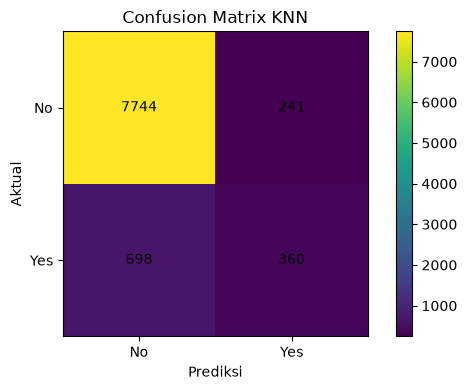

In [20]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 4))

plt.imshow(cm, interpolation="nearest")
plt.title("Confusion Matrix KNN")
plt.xlabel("Prediksi")
plt.ylabel("Aktual")

plt.xticks([0, 1], ["No", "Yes"])
plt.yticks([0, 1], ["No", "Yes"])

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.colorbar()
plt.tight_layout()
plt.show()

# 16. Kesimpulan dan Ringkasan Alur Kerja Machine Learning

Tahap ini merupakan bagian akhir dari rangkaian eksperimen Machine Learning yang kita lakukan. Di sini, kita merangkum kembali informasi penting mengenai dataset yang digunakan, ukuran pembagian data, algoritma yang diterapkan, hingga hasil akhir tingkat akurasi yang berhasil dicapai oleh model K-Nearest Neighbors (KNN). Penjelasan detail dari setiap baris kode di atas adalah sebagai berikut:

* **`print("===== KESIMPULAN MACHINE LEARNING =====")`**  
  Berfungsi untuk mencetak teks judul pembatas dengan dekorasi garis agar tampilan hasil ringkasan di konsol terlihat rapi, formal, dan mudah dibedakan dari *output* proses sebelumnya.

* **`print("Dataset: Bank Marketing")`**  
  Berfungsi untuk mencetak informasi nama domain dataset yang digunakan dalam pembuatan model ini, yaitu *Bank Marketing*.

* **`print("Jumlah seluruh data:", len(df))`**  
  Berfungsi untuk menampilkan informasi total keseluruhan baris sampel data yang dimuat dari DataFrame awal menggunakan fungsi `len(df)`.

* **`print("Jumlah fitur:", X.shape[1])`**  
  Berfungsi untuk menampilkan informasi total kolom atribut atau fitur independen yang digunakan untuk proses pelatihan melalui atribut `.shape[1]`.

* **`print("Algoritma: K-Nearest Neighbors (KNN)")`**  
  Berfungsi untuk mencetak jenis algoritma Machine Learning yang digunakan pada eksperimen ini, yaitu **K-Nearest Neighbors (KNN)**.

* **`print("Data training:", len(X_train))`** dan **`print("Data testing:", len(X_test))`**  
  Berfungsi untuk mencetak informasi jumlah pembagian porsi data, masing-masing untuk data pelatihan (*training*) dan data pengujian (*testing*).

* **`print(f"Akurasi model: {akurasi * 100:.2f}%")`**  
  Berfungsi untuk menampilkan skor akurasi akhir model dalam bentuk persentase dengan pembulatan dua digit desimal yang diambil dari variabel `akurasi` yang telah dihitung sebelumnya.

* **Blok `print("\nKesimpulan:")` dan teks penjelasan berikutnya**  
  Berfungsi untuk mencetak narasi penutup secara bertahap. Teks baris baru (`\n`) digunakan untuk memberikan jarak spasi agar laporan kesimpulan terlihat bersih, yang merangkum bahwa model KNN telah sukses dilatih, dievaluasi, dan siap digunakan untuk memprediksi perilaku nasabah berdasarkan data yang ada.

In [21]:
print("===== KESIMPULAN MACHINE LEARNING =====")
print("Dataset: Bank Marketing")
print("Jumlah seluruh data:", len(df))
print("Jumlah fitur:", X.shape[1])
print("Algoritma: K-Nearest Neighbors (KNN)")
print("Data training:", len(X_train))
print("Data testing:", len(X_test))
print(f"Akurasi model: {akurasi * 100:.2f}%")

print("\nKesimpulan:")
print(
    "Model KNN telah dilatih menggunakan data training "
    "dan dievaluasi menggunakan data testing."
)
print(
    "Model digunakan untuk memprediksi apakah nasabah "
    "akan berlangganan deposito atau tidak."
)
print(
    "Hasil evaluasi menunjukkan performa model pada "
    "dataset pengujian."
)

===== KESIMPULAN MACHINE LEARNING =====
Dataset: Bank Marketing
Jumlah seluruh data: 45211
Jumlah fitur: 16
Algoritma: K-Nearest Neighbors (KNN)
Data training: 36168
Data testing: 9043
Akurasi model: 89.62%

Kesimpulan:
Model KNN telah dilatih menggunakan data training dan dievaluasi menggunakan data testing.
Model digunakan untuk memprediksi apakah nasabah akan berlangganan deposito atau tidak.
Hasil evaluasi menunjukkan performa model pada dataset pengujian.


# 17. Evaluasi Tambahan Menggunakan Metrik Regresi (MAE, RMSE, R2 Score)

Meskipun K-Nearest Neighbors dalam kasus ini digunakan untuk tugas **klasifikasi**, terkadang kita juga ingin mengevaluasi seberapa yakin atau akurat model dalam memprediksi tingkat probabilitas suatu kelas. Pada tahap ini, kita mengubah target label kategori menjadi bentuk numerik biner (0 dan 1) lalu menghitung nilai *Mean Absolute Error* (MAE), *Root Mean Squared Error* (RMSE), dan *R-squared* ($R^2$) dari nilai probabilitas tebakan model. Penjelasan detail dari setiap baris kode di atas adalah sebagai berikut:

* **`from sklearn.metrics import mean_absolute_error` dan baris impor berikutnya**  
  Berfungsi untuk mengimpor fungsi evaluasi tambahan dari modul `sklearn.metrics`, yaitu `mean_absolute_error`, `mean_squared_error`, dan `r2_score`.

* **`y_test_num = (y_test == "yes").astype(int)`**  
  Berfungsi untuk mengubah label teks aktual pada data uji (`y_test`) menjadi bentuk angka biner. Kondisi `y_test == "yes"` akan bernilai `True` (atau 1) jika nasabah berlangganan deposito dan `False` (atau 0) jika tidak. Metode `.astype(int)` mengonversi nilai boolean tersebut menjadi integer angka `1` dan `0` agar dapat dihitung dengan metrik regresi.

* **`y_pred_prob = model.predict_proba(X_test)[:, 1]`**  
  Berfungsi untuk mengambil nilai probabilitas prediksi dari model. Metode `.predict_proba()` mengembalikan array dua kolom (probabilitas kelas "no" di kolom pertama dan probabilitas kelas "yes" di kolom kedua). Penggunaan indeks `[:, 1]` mengambil seluruh baris hanya pada kolom kedua untuk mendapatkan nilai keyakinan model terhadap kelas positif (`"yes"`).

* **`mae = mean_absolute_error(y_test_num, y_pred_prob)`**  
  Berfungsi untuk menghitung rata-rata kesalahan mutlak (*Mean Absolute Error*) antara nilai biner aktual (`y_test_num`) dan probabilitas tebakan model (`y_pred_prob`).

* **`rmse = np.sqrt(mean_squared_error(y_test_num, y_pred_prob))`**  
  Berfungsi untuk menghitung akar kuadrat dari rata-rata kesalahan kuadrat (*Root Mean Squared Error*) guna mengetahui tingkat besar kesalahan prediksi probabilitas.

* **`r2 = r2_score(y_test_num, y_pred_prob)`**  
  Berfungsi untuk menghitung nilai koefisien determinasi ($R^2$) yang menunjukkan seberapa baik variasi dari nilai probabilitas prediksi dapat menjelaskan variasi pada data aktual.

* **Bagian Pencetakan Hasil (`print`)**  
  Berfungsi untuk menampilkan hasil akhir dari perhitungan ketiga metrik tersebut ke layar dengan pembulatan 4 angka di belakang koma menggunakan fungsi `round(..., 4)` agar laporan terlihat rapi dan profesional.

In [22]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error, r2_score

# Mengubah target aktual menjadi angka 0 dan 1
y_test_num = (y_test == "yes").astype(int)

# Mengambil probabilitas prediksi kelas yes
y_pred_prob = model.predict_proba(X_test)[:, 1]

# Menghitung MAE, RMSE, dan R2
mae = mean_absolute_error(y_test_num, y_pred_prob)
rmse = np.sqrt(mean_squared_error(y_test_num, y_pred_prob))
r2 = r2_score(y_test_num, y_pred_prob)

print("=== HASIL EVALUASI ===")
print("MAE :", round(mae, 4))
print("RMSE:", round(rmse, 4))
print("R2  :", round(r2, 4))

=== HASIL EVALUASI ===
MAE : 0.1226
RMSE: 0.2785
R2  : 0.249
